# 02 PCA of fighter style features

Principal component analysis of the **standardized, shrunk** style features from `src/features.py` (full careers, eligible fighters:
5+ UFC fights since 2000). Inputs are `features.clustering_matrix(profiles)`: the 8 within-division z-scores in `CLUSTER_FEATURES`.
`pos_distance` and `tgt_head` are dropped because each is implied by the other two shares in its mix.

**No clustering here.** PCA is computed with NumPy's SVD on mean-centred data. Every input has unit variance, so this is PCA on the
correlation matrix. Component signs are arbitrary; each is flipped so its largest loading is positive.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F

pd.set_option("display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
X = F.clustering_matrix(profiles)
X.columns = [c.removeprefix("z_") for c in X.columns]
info = profiles.set_index("fighter_id").loc[X.index, ["fighter_name", "division", "n_fights"]]
print(f"{X.shape[0]:,} eligible fighters x {X.shape[1]} features; shrinkage prior {F.PRIOR_MINUTES:g} min")
display(X.describe().loc[["mean", "std"]].round(3))

def pca(X):
    Xc = X - X.mean()
    U, s, Vt = np.linalg.svd(Xc.values, full_matrices=False)
    pcs = [f"PC{i + 1}" for i in range(len(s))]
    L = pd.DataFrame(Vt.T, index=X.columns, columns=pcs)
    sign = np.sign([L[c].loc[L[c].abs().idxmax()] for c in pcs])
    L = L * sign
    scores = pd.DataFrame(Xc.values @ L.values, index=X.index, columns=pcs)
    ev = pd.Series(s ** 2 / (s ** 2).sum(), index=pcs)
    return L, scores, ev

L, scores, ev = pca(X)

1,240 eligible fighters x 8 features; shrinkage prior 60 min


,pos_clinch,pos_ground,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
mean,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 1. Explained variance

,explained,cumulative,eigenvalue
PC1,37.5%,37.5%,3.00
PC2,17.5%,55.0%,1.40
PC3,11.1%,66.2%,0.89
PC4,10.8%,76.9%,0.86
PC5,8.3%,85.2%,0.67
PC6,6.7%,92.0%,0.54
PC7,6.0%,98.0%,0.48
PC8,2.0%,100.0%,0.16


Components needed to reach 80%: 5 (85.2%); 4 components give 76.9%. Eigenvalue > 1 (Kaiser rule): 2 components.


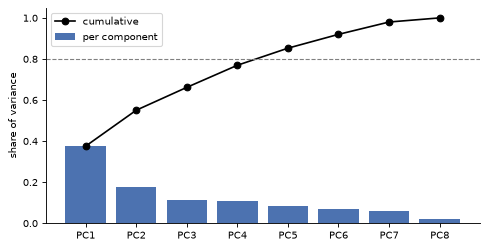

In [2]:
cum = ev.cumsum()
n80 = int((cum >= 0.80).values.argmax()) + 1
display(pd.DataFrame({"explained": ev.map("{:.1%}".format), "cumulative": cum.map("{:.1%}".format),
                      "eigenvalue": (ev * X.shape[1]).round(2)}))
print(f"Components needed to reach 80%: {n80} ({cum.iloc[n80 - 1]:.1%}); "
      f"{n80 - 1} components give {cum.iloc[n80 - 2]:.1%}. Eigenvalue > 1 (Kaiser rule): {int((ev * X.shape[1] > 1).sum())} components.")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, len(ev) + 1), ev.values, color="#4C72B0", label="per component")
ax.plot(range(1, len(ev) + 1), cum.values, marker="o", color="k", label="cumulative")
ax.axhline(0.8, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, len(ev) + 1), ev.index)
ax.set_ylabel("share of variance")
ax.legend()
plt.show()

In [3]:
# Sensitivity: the same PCA without shrinkage (prior = 0)
_, _, ev_raw = pca(F.clustering_matrix(F.build_profiles(None, ff, prior_minutes=0)))
display(pd.DataFrame({"cumulative, shrunk (P = %g)" % F.PRIOR_MINUTES: ev.cumsum().map("{:.1%}".format),
                      "cumulative, raw (P = 0)": ev_raw.cumsum().map("{:.1%}".format)}).T)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
"cumulative, shrunk (P = 60)",37.5%,55.0%,66.2%,76.9%,85.2%,92.0%,98.0%,100.0%
"cumulative, raw (P = 0)",36.3%,54.0%,65.4%,76.5%,84.8%,91.5%,97.9%,100.0%


## 2. Loadings

In [4]:
K = 5
display(L.iloc[:, :K].round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.8, vmax=0.8).format("{:.2f}"))
for c in L.columns[:K]:
    hi = info.loc[scores[c].nlargest(6).index, "fighter_name"].tolist()
    lo = info.loc[scores[c].nsmallest(6).index, "fighter_name"].tolist()
    print(f"{c}  high: {', '.join(hi)}\n     low:  {', '.join(lo)}")

,PC1,PC2,PC3,PC4,PC5
pos_clinch,0.22,0.50,-0.42,0.20,-0.62
pos_ground,0.47,-0.04,-0.01,-0.08,0.04
tgt_body,-0.06,0.64,-0.30,0.10,0.68
tgt_leg,-0.08,0.51,0.64,-0.49,-0.09
td_att_per15,0.45,-0.13,-0.12,-0.38,0.22
ctrl_share,0.52,-0.07,-0.12,-0.25,0.12
sub_att_per15,0.30,-0.02,0.45,0.70,0.21
pace,-0.40,-0.23,-0.29,-0.12,0.18


PC1  high: Pat Sabatini, Jailton Almeida, Tatiana Suarez, Gillian Robertson, Renato Sobral, Matt Lindland
     low:  Sean Strickland, Daniel Rodriguez, John Makdessi, Max Holloway, Chase Sherman, Chris Curtis
PC2  high: Demetrious Johnson, Loma Lookboonmee, Chidi Njokuani, Yana Santos, Brandon Vera, Frankie Saenz
     low:  Khabib Nurmagomedov, Sean Strickland, Jacob Malkoun, Roxanne Modafferi, Serghei Spivac, Evan Dunham
PC3  high: Chris Gutierrez, Ivan Salaverry, Paul Sass, Nathaniel Wood, Johnny Walker, Terry Etim
     low:  Fabio Maldonado, Anthony Hamilton, Angela Hill, Dustin Ortiz, Eryk Anders, Marc-Andre Barriault
PC4  high: Paul Sass, Chris Lytle, John Albert, Dustin Hazelett, Kendall Grove, Jaqueline Amorim
     low:  Chris Gutierrez, Curtis Blaydes, Caol Uno, Merab Dvalishvili, Alexander Volkanovski, Ailin Perez
PC5  high: Michel Pereira, Paulo Costa, Ryan Hall, John Lineker, Bryce Mitchell, Mohammed Usman
     low:  Maycee Barber, Jorge Rivera, BJ Penn, Frankie Saenz, Din T

**Interpretation** (signs as shown above; written from the loadings and the fighters at each end):

- **PC1, grappler ↔ striker.** Positive: ground-strike share, takedown attempts, control share, submission attempts. Negative: pace.
  High scorers are wrestlers and top-control grapplers (Pat Sabatini, Jailton Almeida, Tatiana Suarez). Low scorers are high-volume
  strikers who rarely grapple (Sean Strickland, Max Holloway). This is the dominant style axis.
- **PC2, clinch/body/leg striker ↔ head-hunter at range.** Positive: clinch share, body share, leg share. Negative: pace, mildly.
  High: Muay Thai-flavoured strikers who work the body and clinch (Demetrious Johnson, Loma Lookboonmee, Yana Santos). Low: fighters
  whose strikes go overwhelmingly to the head, from both striking and grappling backgrounds (Strickland, Khabib Nurmagomedov). It
  measures *where* the strikes go, not whether the fighter grapples.
- **PC3, leg kicks (and submissions) ↔ clinch and body work.** Positive: leg share and submission attempts. Negative: clinch, body
  share and pace. High: leg kickers (Chris Gutierrez). Low: clinch/body strikers. It mixes two things, so it's the weakest to interpret.
- **PC4, submission hunter ↔ takedown-and-control wrestler.** Positive: submission attempts. Negative: leg share, takedown attempts,
  control. It separates grapplers who hunt submissions (Paul Sass, Chris Lytle, Dustin Hazelett) from wrestlers who take down and hold
  without submitting (Merab Dvalishvili, Curtis Blaydes). PC1 lumps the two together.
- **PC5 and later** are mostly contrasts between clinch share and body share, and explain less than one input feature each.

## 3. Fighters on the first two components

All eligible fighters in grey. About 20 well-known fighters labelled. The right panel shows each feature's loadings on PC1 and PC2.

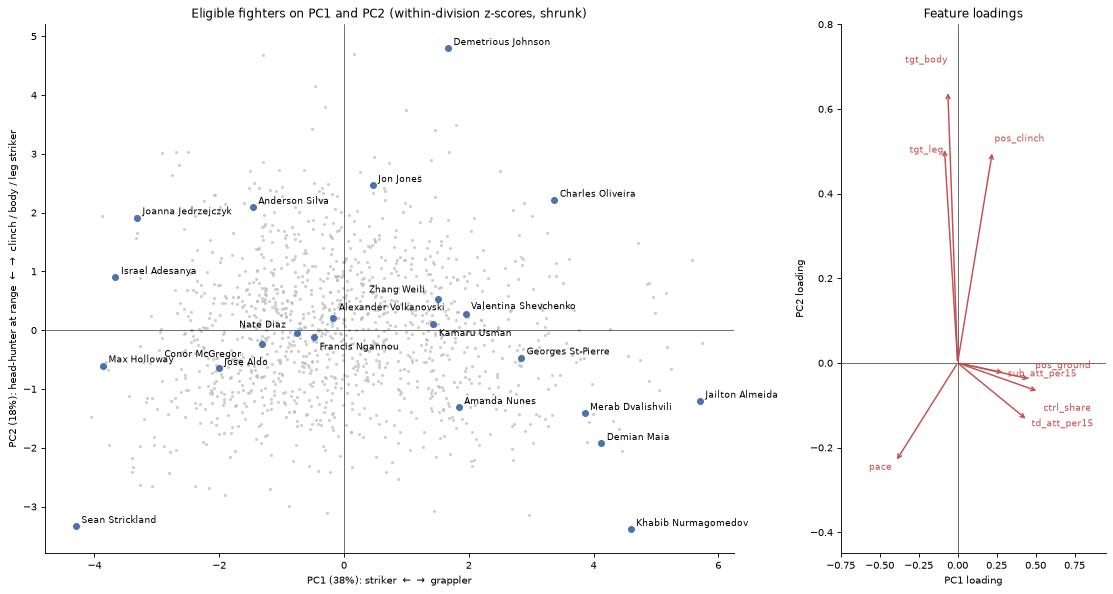

,PC1,PC2,PC3,PC4
Georges St-Pierre,2.84,-0.47,0.95,-1.00
Khabib Nurmagomedov,4.60,-3.39,-0.48,-1.58
Jon Jones,0.46,2.46,0.82,-1.21
Anderson Silva,-1.46,2.09,1.46,0.01
Conor McGregor,-1.31,-0.23,-0.46,-0.18
Israel Adesanya,-3.66,0.90,1.82,-0.90
Max Holloway,-3.86,-0.60,-1.13,0.39
Demian Maia,4.13,-1.93,-0.22,-0.37
Charles Oliveira,3.37,2.21,0.96,2.62
Merab Dvalishvili,3.86,-1.41,-1.79,-2.61


In [5]:
LABEL = ["Georges St-Pierre", "Khabib Nurmagomedov", "Jon Jones", "Anderson Silva", "Conor McGregor", "Israel Adesanya",
         "Max Holloway", "Demian Maia", "Charles Oliveira", "Merab Dvalishvili", "Jose Aldo", "Francis Ngannou",
         "Amanda Nunes", "Valentina Shevchenko", "Zhang Weili", "Joanna Jedrzejczyk", "Alexander Volkanovski", "Kamaru Usman",
         "Nate Diaz", "Jailton Almeida", "Sean Strickland", "Demetrious Johnson"]
name_to_id = dict(zip(info["fighter_name"], info.index))
missing = [n for n in LABEL if n not in name_to_id]
if missing:
    print("not eligible / not found:", missing)

OFFSET = {"Francis Ngannou": (5, -11), "Conor McGregor": (-88, -12), "Nate Diaz": (-52, 5), "Alexander Volkanovski": (5, 7),
          "Kamaru Usman": (5, -11), "Zhang Weili": (-62, 6), "Valentina Shevchenko": (5, 4)}
fig, (ax, axl) = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [2.6, 1]})
ax.scatter(scores["PC1"], scores["PC2"], s=8, color="#bbbbbb", alpha=0.7, lw=0)
for n in LABEL:
    if n in name_to_id:
        x, y = scores.loc[name_to_id[n], ["PC1", "PC2"]]
        ax.scatter([x], [y], s=28, color="#4C72B0", zorder=3)
        ax.annotate(n, (x, y), xytext=OFFSET.get(n, (5, 3)), textcoords="offset points", fontsize=8.5, zorder=4)
for a in (ax, axl):
    a.axhline(0, color="k", lw=0.5)
    a.axvline(0, color="k", lw=0.5)
ax.set_xlabel(f"PC1 ({ev['PC1']:.0%}): striker  ←  →  grappler")
ax.set_ylabel(f"PC2 ({ev['PC2']:.0%}): head-hunter at range  ←  →  clinch / body / leg striker")
ax.set_title("Eligible fighters on PC1 and PC2 (within-division z-scores, shrunk)")
for f in L.index:
    x, y = L.loc[f, "PC1"], L.loc[f, "PC2"]
    axl.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1.3))
    axl.text(x * 1.06, y * 1.06 + (0.035 if f in ("pos_ground", "tgt_body") else -0.035 if f in ("ctrl_share", "tgt_leg") else 0),
             f, color="#C44E52", fontsize=8.5, ha="left" if x >= 0 else "right", va="center")
axl.set_xlim(-0.75, 0.95)
axl.set_ylim(-0.45, 0.8)
axl.set_xlabel("PC1 loading")
axl.set_ylabel("PC2 loading")
axl.set_title("Feature loadings")
fig.tight_layout()
plt.show()
display(scores.loc[[name_to_id[n] for n in LABEL if n in name_to_id], ["PC1", "PC2", "PC3", "PC4"]]
        .set_axis([n for n in LABEL if n in name_to_id]).round(2))

## 4. Notes for clustering

- Variance is spread out. PC1 explains about 38%, and it takes 5 components to pass 80%. So the 8 inputs aren't dominated by one
  or two axes, and a clustering on all 8 z-scores and one on the first 4 or 5 PCs could give noticeably different groupings.
- PC1 combines all the grappling features. Distance-based clustering on the raw z-scores weights "grappling" roughly 4 times
  (ground share, takedowns, control, submissions) against 1 feature for pace. That's worth keeping in mind when choosing inputs.